# 4 · Autoencoders and VAEs on colored shapes

Can a model learn to draw a square, diamond, circle or triangle in red, green or blue?
We make our own dataset, compress images with an autoencoder, then add a KL term
so that we can sample new images from a VAE. No downloads needed.

## Setup

In [95]:
import time
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from PIL import Image, ImageDraw
from torch.utils.data import DataLoader, TensorDataset

QUICK = True
SEED = 42
IMAGE_SIZE = 32
LATENT = 8

torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
if device.type == "cpu":
    torch.set_num_threads(min(4, torch.get_num_threads()))
plt.rcParams["figure.dpi"] = 100
print("device:", device, "| QUICK:", QUICK)


def show_images(images, titles=None, ncols=6, title=None):
    nrows = int(np.ceil(len(images) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(ncols * 1.5, nrows * 1.7))
    axes = np.atleast_1d(axes).ravel()
    for ax in axes:
        ax.axis("off")
    for i, img in enumerate(images):
        axes[i].imshow(img.detach().cpu().permute(1, 2, 0).clamp(0, 1).numpy())
        if titles is not None:
            axes[i].set_title(titles[i], fontsize=8)
    if title:
        fig.suptitle(title)
    plt.tight_layout()
    plt.show()

device: cuda | QUICK: True


## 1. Make the dataset

Four shapes × three colors = 12 combinations, all equally common.
Each image contains one shape on a black background. We vary its size and position
slightly, keeping orientation fixed so that a diamond stays distinct from a square.
We draw at higher resolution and downsample for smooth edges.

We generate training and validation examples with separate seeds. Labels are only
used to inspect results: neither model receives a shape or color label.

train: 2400 | validation: 360 | 12 balanced combinations


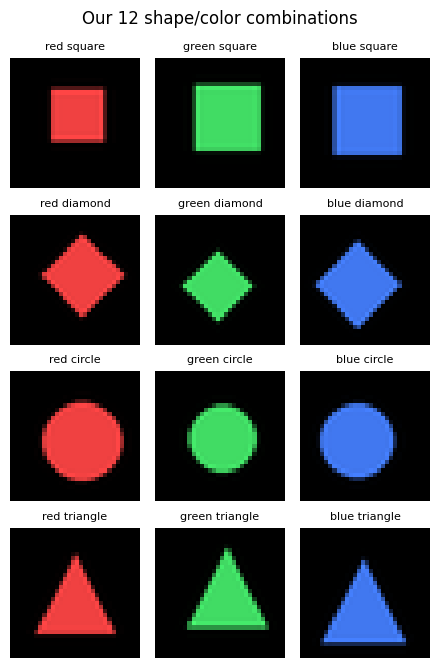

In [96]:
SHAPES = ("square", "diamond", "circle", "triangle")
COLOR_NAMES = ("red", "green", "blue")
COLORS = ((240, 65, 65), (65, 220, 100), (65, 120, 240))


def draw_shape(shape, color, rng):
    scale = 3
    canvas = Image.new("RGB", (IMAGE_SIZE * scale, IMAGE_SIZE * scale), "black")
    draw = ImageDraw.Draw(canvas)
    cx, cy = (IMAGE_SIZE / 2 + rng.uniform(-2, 2, size=2)) * scale
    r = rng.uniform(8, 11) * scale
    fill = COLORS[color]
    if shape == 0:
        # Smaller half-width keeps square area comparable to the other shapes.
        h = r * 0.8
        draw.rectangle((cx-h, cy-h, cx+h, cy+h), fill=fill)
    elif shape == 1:
        draw.polygon([(cx, cy-r), (cx+r, cy), (cx, cy+r), (cx-r, cy)], fill=fill)
    elif shape == 2:
        draw.ellipse((cx-r, cy-r, cx+r, cy+r), fill=fill)
    else:
        draw.polygon([(cx, cy-r), (cx+r, cy+r), (cx-r, cy+r)], fill=fill)
    image = canvas.resize((IMAGE_SIZE, IMAGE_SIZE), Image.Resampling.LANCZOS)
    return torch.from_numpy(np.array(image, dtype=np.float32) / 255).permute(2, 0, 1)


def make_shapes(per_combination, seed):
    rng = np.random.default_rng(seed)
    images, labels = [], []
    for shape in range(len(SHAPES)):
        for color in range(len(COLORS)):
            for _ in range(per_combination):
                images.append(draw_shape(shape, color, rng))
                labels.append(shape * len(COLORS) + color)
    return TensorDataset(torch.stack(images), torch.tensor(labels))


train_data = make_shapes(200 if QUICK else 500, SEED)
val_data = make_shapes(30, SEED + 1)
train_loader = DataLoader(train_data, batch_size=128, shuffle=True,
                          generator=torch.Generator().manual_seed(SEED))
val_loader = DataLoader(val_data, batch_size=128, shuffle=False)
print(f"train: {len(train_data)} | validation: {len(val_data)} | 12 balanced combinations")

# One example of every combination: rows = shapes, columns = colors.
example_indices = [label * 30 for label in range(12)]
example_images = torch.stack([val_data[i][0] for i in example_indices])
example_titles = [f"{color} {shape}" for shape in SHAPES for color in COLOR_NAMES]
show_images(example_images, example_titles, ncols=3, title="Our 12 shape/color combinations")

## 2. Build an autoencoder

The encoder compresses a 32×32 RGB image (3,072 values) into eight numbers.
The decoder tries to rebuild the image. Binary cross-entropy measures the
reconstruction error; the sigmoid output keeps predicted intensities between 0 and 1.
The same loss also supports our smooth, fractional edge pixels.

In [97]:
def encoder():
    return nn.Sequential(
        nn.Conv2d(3, 16, 4, stride=2, padding=1), nn.ReLU(),   # 32 -> 16
        nn.Conv2d(16, 32, 4, stride=2, padding=1), nn.ReLU(),  # 16 -> 8
        nn.Conv2d(32, 64, 4, stride=2, padding=1), nn.ReLU(),  # 8 -> 4
        nn.Flatten(),
    )


def decoder():
    return nn.Sequential(
        nn.Unflatten(1, (64, 4, 4)),
        nn.ConvTranspose2d(64, 32, 4, stride=2, padding=1), nn.ReLU(),
        nn.ConvTranspose2d(32, 16, 4, stride=2, padding=1), nn.ReLU(),
        nn.ConvTranspose2d(16, 3, 4, stride=2, padding=1), nn.Sigmoid(),
    )


class AE(nn.Module):
    def __init__(self, latent=LATENT):
        super().__init__()
        self.enc = encoder()
        self.to_latent = nn.Linear(64 * 4 * 4, latent)
        self.from_latent = nn.Linear(latent, 64 * 4 * 4)
        self.dec = decoder()

    def encode(self, x):
        return self.to_latent(self.enc(x))

    def decode(self, z):
        return self.dec(self.from_latent(z))

    def forward(self, x):
        z = self.encode(x)
        return z, self.decode(z)


def train_ae(model, epochs, lr=1e-3):
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    for epoch in range(epochs):
        t0 = time.time()
        model.train()
        running = 0.0
        for xb, _ in train_loader:
            xb = xb.to(device)
            opt.zero_grad()
            _, rec = model(xb)
            loss = F.binary_cross_entropy(rec, xb)
            loss.backward()
            opt.step()
            running += loss.item() * len(xb)
        print(f"epoch {epoch+1}/{epochs} | BCE/pixel {running/len(train_data):.4f}"
              f" | {time.time()-t0:.1f}s")
    return model


ae = AE().to(device)
print(f"autoencoder parameters: {sum(p.numel() for p in ae.parameters()):,}")
train_ae(ae, epochs=60 if QUICK else 100)

autoencoder parameters: 101,035
epoch 1/60 | BCE/pixel 0.6324 | 0.1s
epoch 2/60 | BCE/pixel 0.3131 | 0.1s
epoch 3/60 | BCE/pixel 0.2385 | 0.1s
epoch 4/60 | BCE/pixel 0.2274 | 0.1s
epoch 5/60 | BCE/pixel 0.2228 | 0.1s
epoch 6/60 | BCE/pixel 0.2202 | 0.1s
epoch 7/60 | BCE/pixel 0.2185 | 0.1s
epoch 8/60 | BCE/pixel 0.2168 | 0.1s
epoch 9/60 | BCE/pixel 0.2109 | 0.1s
epoch 10/60 | BCE/pixel 0.1988 | 0.1s
epoch 11/60 | BCE/pixel 0.1921 | 0.1s
epoch 12/60 | BCE/pixel 0.1888 | 0.1s
epoch 13/60 | BCE/pixel 0.1865 | 0.1s
epoch 14/60 | BCE/pixel 0.1847 | 0.1s
epoch 15/60 | BCE/pixel 0.1836 | 0.1s
epoch 16/60 | BCE/pixel 0.1825 | 0.1s
epoch 17/60 | BCE/pixel 0.1816 | 0.1s
epoch 18/60 | BCE/pixel 0.1807 | 0.1s
epoch 19/60 | BCE/pixel 0.1800 | 0.1s
epoch 20/60 | BCE/pixel 0.1793 | 0.1s
epoch 21/60 | BCE/pixel 0.1785 | 0.1s
epoch 22/60 | BCE/pixel 0.1775 | 0.1s
epoch 23/60 | BCE/pixel 0.1765 | 0.1s
epoch 24/60 | BCE/pixel 0.1752 | 0.1s
epoch 25/60 | BCE/pixel 0.1737 | 0.1s
epoch 26/60 | BCE/pixel 0.1

AE(
  (enc): Sequential(
    (0): Conv2d(3, 16, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (1): ReLU()
    (2): Conv2d(16, 32, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (3): ReLU()
    (4): Conv2d(32, 64, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (5): ReLU()
    (6): Flatten(start_dim=1, end_dim=-1)
  )
  (to_latent): Linear(in_features=1024, out_features=8, bias=True)
  (from_latent): Linear(in_features=8, out_features=1024, bias=True)
  (dec): Sequential(
    (0): Unflatten(dim=1, unflattened_size=(64, 4, 4))
    (1): ConvTranspose2d(64, 32, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (2): ReLU()
    (3): ConvTranspose2d(32, 16, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (4): ReLU()
    (5): ConvTranspose2d(16, 3, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (6): Sigmoid()
  )
)

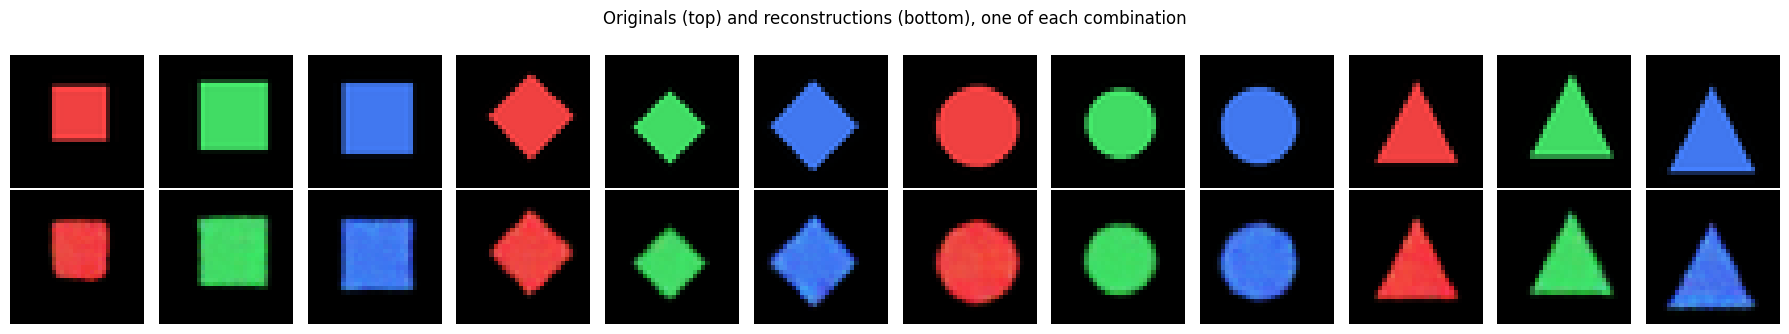

In [98]:
@torch.no_grad()
def reconstruction_grid(model, variational=False):
    model.eval()
    x = example_images.to(device)
    if variational:
        mu, _ = model.encode(x)
        rec = model.decode(mu)  # use the mean for a stable comparison
    else:
        _, rec = model(x)
    show_images(list(x.cpu()) + list(rec.cpu()), ncols=12,
                title="Originals (top) and reconstructions (bottom), one of each combination")


reconstruction_grid(ae)

## 3. Why not just decode random numbers?

An autoencoder only learns to decode vectors produced by its encoder.
It does not require those vectors to follow N(0, I). Inspect their means and
standard deviations, then try decoding standard normal noise.
Even matching these statistics would not guarantee that the latent space has no gaps.

latent means: [9.1899995803833, -0.41999998688697815, -9.970000267028809, -21.239999771118164, 2.9800000190734863, 13.539999961853027, 32.22999954223633, -2.7300000190734863]
latent stds:  [12.430000305175781, 10.5, 12.279999732971191, 8.479999542236328, 11.600000381469727, 15.670000076293945, 14.739999771118164, 11.579999923706055]


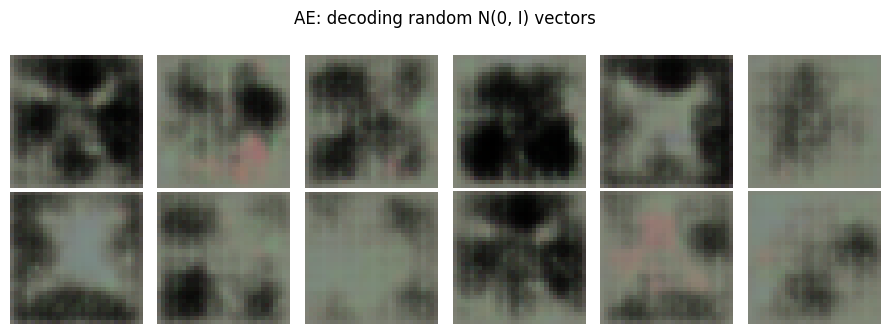

In [99]:
ae.eval()
with torch.no_grad():
    z_vals = torch.cat([ae.encode(x.to(device)).cpu() for x, _ in val_loader])
    random_ae = ae.decode(torch.randn(12, LATENT, device=device)).cpu()
print("latent means:", z_vals.mean(0).round(decimals=2).tolist())
print("latent stds: ", z_vals.std(0).round(decimals=2).tolist())
show_images(random_ae, ncols=6, title="AE: decoding random N(0, I) vectors")

## 4. Turn the autoencoder into a VAE

The encoder now predicts a mean and log-variance. We sample with
`z = μ + σ · ε`, where `ε ~ N(0, I)`. This reparameterisation lets gradients
flow through the sample.

The loss has two parts: reconstruction error and a KL penalty that encourages
encoded distributions to stay close to N(0, I). Both terms are **summed per image,
then averaged over the batch**. We gradually increase the KL weight during the
first five epochs so the decoder can first learn to draw.

In [100]:
class VAE(nn.Module):
    def __init__(self, latent=LATENT):
        super().__init__()
        self.enc = encoder()
        self.fc_mu = nn.Linear(64 * 4 * 4, latent)
        self.fc_logvar = nn.Linear(64 * 4 * 4, latent)
        self.from_latent = nn.Linear(latent, 64 * 4 * 4)
        self.dec = decoder()

    def encode(self, x):
        h = self.enc(x)
        return self.fc_mu(h), self.fc_logvar(h)

    def reparameterise(self, mu, logvar):
        return mu + torch.exp(0.5 * logvar) * torch.randn_like(mu)

    def decode(self, z):
        return self.dec(self.from_latent(z))

    def forward(self, x):
        mu, logvar = self.encode(x)
        return self.decode(self.reparameterise(mu, logvar)), mu, logvar


def vae_loss(rec, x, mu, logvar, beta=1.0):
    recon = F.binary_cross_entropy(rec, x, reduction="none").flatten(1).sum(1).mean()
    kl = -0.5 * (1 + logvar - mu.pow(2) - logvar.exp()).sum(1).mean()
    return recon + beta * kl, recon, kl


def train_vae(model, epochs, lr=1e-3, beta=1.0):
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    for epoch in range(epochs):
        t0 = time.time()
        model.train()
        r_sum, k_sum = 0.0, 0.0
        weight = beta * min(1.0, (epoch + 1) / 5)
        for xb, _ in train_loader:
            xb = xb.to(device)
            opt.zero_grad()
            rec, mu, logvar = model(xb)
            loss, r, k = vae_loss(rec, xb, mu, logvar, weight)
            loss.backward()
            opt.step()
            r_sum += r.item() * len(xb)
            k_sum += k.item() * len(xb)
        print(f"epoch {epoch+1}/{epochs} | recon/image {r_sum/len(train_data):.1f}"
              f" | KL/image {k_sum/len(train_data):.2f} | beta {weight:.2f}"
              f" | {time.time()-t0:.1f}s")
    return model


vae = VAE().to(device)
train_vae(vae, epochs=100 if QUICK else 180, beta=1.0)

epoch 1/100 | recon/image 1932.2 | KL/image 46.53 | beta 0.20 | 0.1s
epoch 2/100 | recon/image 912.7 | KL/image 103.82 | beta 0.40 | 0.1s
epoch 3/100 | recon/image 715.6 | KL/image 36.51 | beta 0.60 | 0.1s
epoch 4/100 | recon/image 688.5 | KL/image 18.66 | beta 0.80 | 0.1s
epoch 5/100 | recon/image 677.3 | KL/image 14.97 | beta 1.00 | 0.1s
epoch 6/100 | recon/image 664.7 | KL/image 14.55 | beta 1.00 | 0.1s
epoch 7/100 | recon/image 632.4 | KL/image 16.86 | beta 1.00 | 0.1s
epoch 8/100 | recon/image 612.1 | KL/image 16.53 | beta 1.00 | 0.1s
epoch 9/100 | recon/image 595.8 | KL/image 16.97 | beta 1.00 | 0.1s
epoch 10/100 | recon/image 588.1 | KL/image 16.42 | beta 1.00 | 0.1s
epoch 11/100 | recon/image 581.4 | KL/image 16.08 | beta 1.00 | 0.1s
epoch 12/100 | recon/image 576.1 | KL/image 15.65 | beta 1.00 | 0.1s
epoch 13/100 | recon/image 571.5 | KL/image 14.85 | beta 1.00 | 0.1s
epoch 14/100 | recon/image 568.5 | KL/image 14.59 | beta 1.00 | 0.1s
epoch 15/100 | recon/image 566.4 | KL/ima

VAE(
  (enc): Sequential(
    (0): Conv2d(3, 16, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (1): ReLU()
    (2): Conv2d(16, 32, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (3): ReLU()
    (4): Conv2d(32, 64, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (5): ReLU()
    (6): Flatten(start_dim=1, end_dim=-1)
  )
  (fc_mu): Linear(in_features=1024, out_features=8, bias=True)
  (fc_logvar): Linear(in_features=1024, out_features=8, bias=True)
  (from_latent): Linear(in_features=8, out_features=1024, bias=True)
  (dec): Sequential(
    (0): Unflatten(dim=1, unflattened_size=(64, 4, 4))
    (1): ConvTranspose2d(64, 32, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (2): ReLU()
    (3): ConvTranspose2d(32, 16, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (4): ReLU()
    (5): ConvTranspose2d(16, 3, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (6): Sigmoid()
  )
)

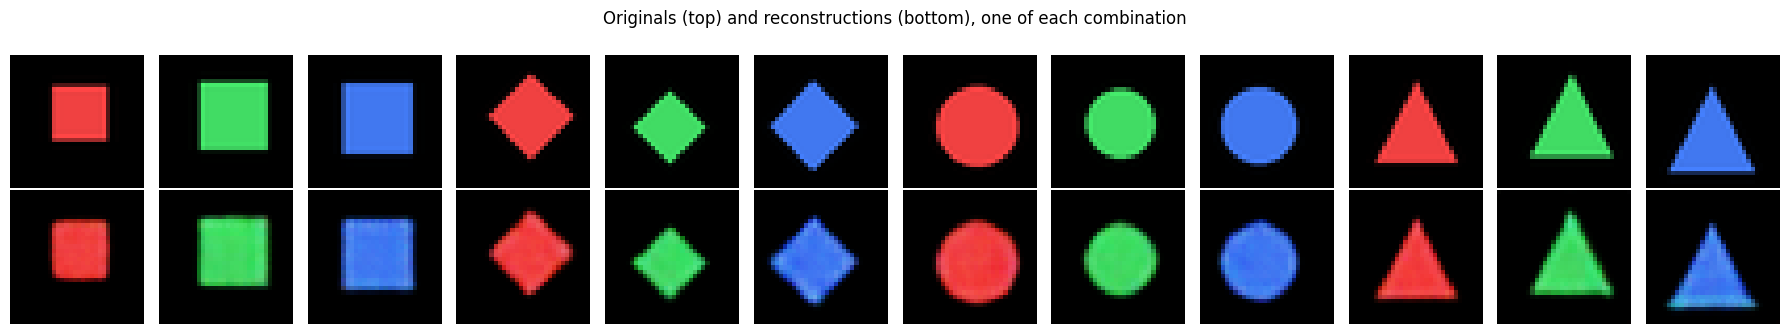

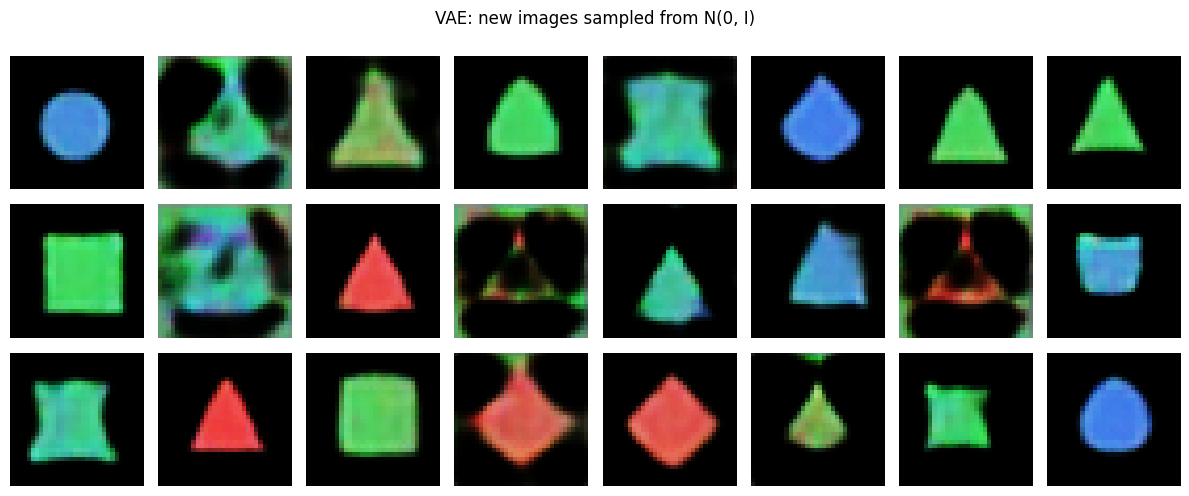

In [101]:
reconstruction_grid(vae, variational=True)

@torch.no_grad()
def vae_samples(model, n=24):
    model.eval()
    return model.decode(torch.randn(n, LATENT, device=device)).cpu()


show_images(vae_samples(vae), ncols=8, title="VAE: new images sampled from N(0, I)")

## 5. Inspect the latent space

Project the validation images' encoded means onto their first two principal
components. Color indicates the original color; marker indicates the original shape.
Labels are used only for this plot. This is a 2D projection of eight dimensions,
so overlapping points here need not overlap in the full latent space.

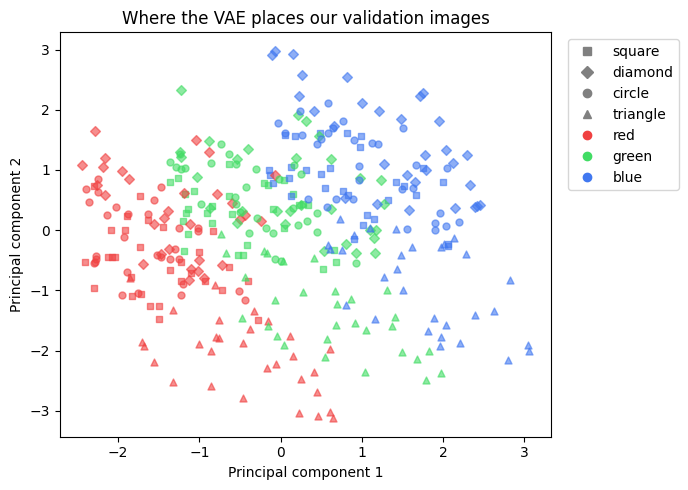

In [102]:
vae.eval()
with torch.no_grad():
    means = torch.cat([vae.encode(x.to(device))[0].cpu() for x, _ in val_loader])
labels = val_data.tensors[1].numpy()
centered = means - means.mean(0)
_, _, vh = torch.linalg.svd(centered, full_matrices=False)
points = (centered @ vh[:2].T).numpy()
markers = ("s", "D", "o", "^")
plot_colors = np.array(COLORS) / 255
fig, ax = plt.subplots(figsize=(7, 5))
for shape in range(4):
    for color in range(3):
        mask = labels == shape * 3 + color
        ax.scatter(*points[mask].T, color=plot_colors[color], marker=markers[shape],
                   s=25, alpha=0.6)
handles = [Line2D([], [], marker=m, color="gray", linestyle="", label=s)
           for m, s in zip(markers, SHAPES)]
handles += [Line2D([], [], marker="o", color=c, linestyle="", label=n)
            for c, n in zip(plot_colors, COLOR_NAMES)]
ax.legend(handles=handles, bbox_to_anchor=(1.02, 1), loc="upper left")
ax.set(xlabel="Principal component 1", ylabel="Principal component 2",
       title="Where the VAE places our validation images")
plt.tight_layout()
plt.show()

## 6. Walk between two images

Decode points on a straight line between two encoded means. The first and last
panels are the actual inputs; the middle panels are decoder outputs, including the
reconstructed endpoints.

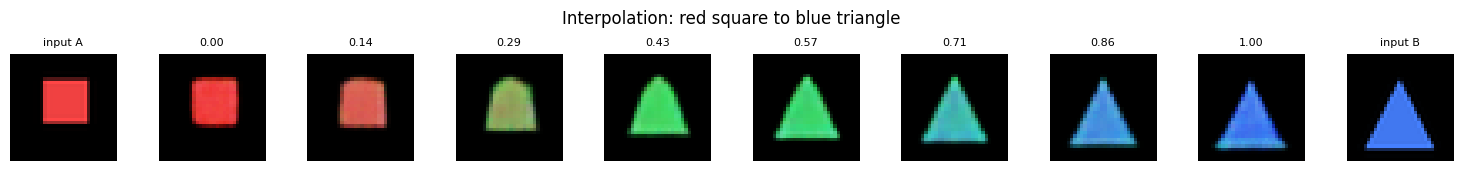

In [103]:
@torch.no_grad()
def interpolate(model, x1, x2, steps=8):
    model.eval()
    mu1, _ = model.encode(x1.unsqueeze(0).to(device))
    mu2, _ = model.encode(x2.unsqueeze(0).to(device))
    alpha = torch.linspace(0, 1, steps, device=device).unsqueeze(1)
    return model.decode((1 - alpha) * mu1 + alpha * mu2).cpu()


# Indices follow the 12-example grid: red/green/blue square, then diamond, etc.
a, b = example_images[0], example_images[11]  # red square -> blue triangle
frames = interpolate(vae, a, b)
show_images([a] + list(frames) + [b],
            titles=["input A"] + [f"{t:.2f}" for t in np.linspace(0, 1, len(frames))] + ["input B"],
            ncols=10, title="Interpolation: red square to blue triangle")